# Primary statistical analysis and sensitivity checks
## Scope
Only the original 896 attempts enter this notebook: 890 valid graphs, six failures and 12 valid empty graphs. The selectively completed six supplemental graphs remain separate.
The fixed family is 24 within-method contrasts against US-English. Four models are averaged within eight paired schedule blocks; nodes, edges and model rows are not extra independent replications.
These outputs concern one fictional roster and four fixed model configurations. They do not prove national cultural behavior, equivalence or human-network realism.

**Revision 3:** the primary figure flags omission sensitivity; the numerical checks below are unchanged.

In [1]:
from pathlib import Path
import sys, json, hashlib
import pandas as pd
from IPython.display import display, Markdown, Image
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'analysis_primary/core.py').is_file())
sys.path.insert(0, str(ROOT))
from analysis_primary.core import load_inputs, block_table, independent_contrasts, compare_frozen, archived_agreement
OUT = ROOT / 'outputs/primary_analysis/20261105'
manifest = json.loads((OUT / 'evaluation_manifest.json').read_text())
assert manifest['status'] == 'COMPLETE_PRIMARY_ANALYSIS_WITH_CAVEATS'
assert manifest['supplemental_graphs_in_inference'] == 0
for name, info in manifest['artifacts'].items():
    path = OUT / name
    assert path.stat().st_size == info['bytes'] and hashlib.sha256(path.read_bytes()).hexdigest() == info['sha256'], name
for name, expected in manifest['code_sha256'].items():
    assert hashlib.sha256((ROOT / name).read_bytes()).hexdigest() == expected, name
spec, primary, original_rows = load_inputs(ROOT)
print('Validated primary cohort:', len(primary), 'attempts,', int(primary.valid_graph.sum()), 'valid graphs.')

from analysis_figures.publication_v3 import show


Validated primary cohort: 896 attempts, 890 valid graphs.


## Recompute the locked primary family
Global uses density; local, sequential and iterative use mean clustering. Differences are target instruction minus same-seed US-English.
Inference requires all four models in both arms of a block and at least six complete blocks. The family always retains 24 hypotheses. Holm-adjusted p-values and 95% familywise Bonferroni simultaneous t intervals remain assumption-dependent.
The next cell reruns the frozen statistical function, independently checks its arithmetic from paired blocks and verifies agreement with the archive; it does not rewrite original results.

In [2]:
from final_study import analysis as frozen_analysis
contrasts = frozen_analysis.primary_contrasts(original_rows, spec['analysis'])
blocks = block_table(primary, spec)
independent = independent_contrasts(blocks, spec)
compare_frozen(contrasts, independent)
archived = json.loads((ROOT / 'outputs/final_study/060dcd3a86d5/main/primary_contrasts.json').read_text())
display(archived_agreement(contrasts, archived))
table = pd.DataFrame(contrasts)
display(table[['hypothesis_id','complete_schedule_blocks','complete_block_mean','status','raw_p','holm_p','simultaneous_ci']])


{'absolute_tolerance': 1e-12,
 'numeric_fields_differing': 5,
 'maximum_absolute_difference': 1.1102230246251565e-16,
 'identity_and_status_exact': True}

,hypothesis_id,complete_schedule_blocks,complete_block_mean,status,raw_p,holm_p,simultaneous_ci
0,global:india:english,8,-0.003010,COMPLETE_ASSUMPTIONS_REQUIRED,0.612181,1.000000,"[-0.029964107099990867, 0.023943698936725565]"
1,global:japan:english,8,-0.002194,COMPLETE_ASSUMPTIONS_REQUIRED,0.662685,1.000000,"[-0.02508269126155368, 0.020694936159512865]"
2,global:brazil:english,8,-0.001199,COMPLETE_ASSUMPTIONS_REQUIRED,0.833231,1.000000,"[-0.02725747968380711, 0.02485952050013364]"
3,global:us:hindi,8,0.009668,COMPLETE_ASSUMPTIONS_REQUIRED,0.034216,0.615892,"[-0.007834598266211384, 0.02717133296008893]"
4,global:us:japanese,5,0.003633,MISSING_NO_INFERENCE,NaN,NaN,None
5,global:us:portuguese,6,0.006565,PARTIAL_BLOCKS_ASSUMPTIONS_REQUIRED,0.527457,1.000000,"[-0.04991762859769603, 0.06304688029837631]"
6,local:india:english,8,0.006068,COMPLETE_ASSUMPTIONS_REQUIRED,0.296030,1.000000,"[-0.019456949057618744, 0.03159219254559739]"
7,local:japan:english,8,-0.013193,COMPLETE_ASSUMPTIONS_REQUIRED,0.014385,0.287703,"[-0.032573613522871206, 0.006188543081348901]"
8,local:brazil:english,8,0.002192,COMPLETE_ASSUMPTIONS_REQUIRED,0.749154,1.000000,"[-0.029105092670097713, 0.03348825816510119]"
9,local:us:hindi,8,-0.017113,COMPLETE_ASSUMPTIONS_REQUIRED,0.008989,0.206743,"[-0.03982605191899231, 0.005599872238038393]"


## Sensitivity is not a new primary result
Exact two-sided sign flips are a post-collection symmetry diagnostic, not causal randomization inference. They require exchangeable signs under their null, not merely a zero mean. With eight blocks their minimum possible two-sided p-value is 2/256; 24-way adjustment has low resolution.
Leave-one-seed-out checks repeat the complete 24-hypothesis adjustment. Missing-value bounds are identification bounds allowing unavailable endpoints anywhere in [0,1], not confidence intervals or a claim of certainty.
A nonsignificant result does not establish sameness: no meaningful-effect/equivalence margin was fixed.

In [3]:
sensitivity = pd.DataFrame(independent)
loo = pd.read_csv(OUT / 'leave_one_seed_out.csv')
display(sensitivity[['hypothesis_id','n','mean','holm_p','sign_flip_p','sign_flip_holm_p','bounded_missingness_lower','bounded_missingness_upper']])
hindi = table[table.hypothesis_id.eq('iterative:us:hindi')].iloc[0]
check = sensitivity[sensitivity.hypothesis_id.eq('iterative:us:hindi')].iloc[0]
omissions = loo[loo.hypothesis_id.eq('iterative:us:hindi')]
print('Iterative Hindi mean difference:', hindi.complete_block_mean)
print('Frozen t/Holm p:', hindi.holm_p, '| exploratory sign-flip/Holm p:', check.sign_flip_holm_p)
print('Leave-one-seed-out Holm < .05:', int(omissions.holm_p.lt(.05).sum()), 'of', len(omissions))
display(omissions)


,hypothesis_id,n,mean,holm_p,sign_flip_p,sign_flip_holm_p,bounded_missingness_lower,bounded_missingness_upper
0,global:india:english,8,-0.003010,1.000000,0.601562,1.000000,-0.003010,-0.003010
1,global:japan:english,8,-0.002194,1.000000,0.687500,1.000000,-0.002194,-0.002194
2,global:brazil:english,8,-0.001199,1.000000,0.875000,1.000000,-0.001199,-0.001199
3,global:us:hindi,8,0.009668,0.615892,0.023438,0.468750,0.009668,0.009668
4,global:us:japanese,5,0.003633,NaN,NaN,NaN,0.001020,0.094770
5,global:us:portuguese,6,0.006565,1.000000,0.500000,1.000000,0.001276,0.063776
6,local:india:english,8,0.006068,1.000000,0.296875,1.000000,0.006068,0.006068
7,local:japan:english,8,-0.013193,0.287703,0.031250,0.593750,-0.013193,-0.013193
8,local:brazil:english,8,0.002192,1.000000,0.742188,1.000000,0.002192,0.002192
9,local:us:hindi,8,-0.017113,0.206743,0.015625,0.359375,-0.017113,-0.017113


Iterative Hindi mean difference: -0.04527889372665199
Frozen t/Holm p: 0.023831222391575133 | exploratory sign-flip/Holm p: 0.1875
Leave-one-seed-out Holm < .05: 3 of 8


,omitted_seed,hypothesis_id,n,mean,raw_p,holm_p
21,44000,iterative:us:hindi,7,-0.037592,0.000062,0.001486
45,44001,iterative:us:hindi,7,-0.045066,0.003437,0.082480
69,44002,iterative:us:hindi,7,-0.047560,0.002180,0.052309
93,44003,iterative:us:hindi,7,-0.047927,0.001952,0.046852
117,44004,iterative:us:hindi,7,-0.048030,0.001888,0.045314
141,44005,iterative:us:hindi,7,-0.045825,0.003140,0.075362
165,44006,iterative:us:hindi,7,-0.044543,0.003575,0.078642
189,44007,iterative:us:hindi,7,-0.045688,0.003201,0.076826


## Graph and resource evaluations
Graph checks cover all 890 valid primary adjacency files. Eight deterministic G(n,m) references per valid graph match node and edge counts; they are synthetic context, not empirical people or proof of realism. Reference SD is Monte Carlo spread, not a confidence interval; density matching is tautological.
Resource summaries include failed graph attempts. Received usage costs exclude unallocated retained reservations, which are separately included in the study total. API seconds are serial provider time, not wall time. More iterative calls prevent an equal-compute method-superiority claim.

{'attempts': 896,
 'baseline_pvalues': False,
 'cohort': 'primary',
 'empirical_ground_truth': False,
 'failed_attempts': 6,
 'files': ['graph_quality.csv',
  'synthetic_reference_per_run.csv',
  'synthetic_reference_descriptive.csv',
  'graph_evaluation.json'],
 'interpretation': 'Equal-n/equal-m synthetic descriptive context only; not empirical ground truth, a realism benchmark, or a new primary hypothesis test. Density is fixed by n,m. Eight draws do not establish null convergence. Efficiency observations are retained from CSV; recomputed efficiency is descriptive, not a frozen-math verification claim.',
 'metric_absolute_tolerance': 1e-12,
 'metric_checks': {'avg_clustering_coef': {'failure': 6,
   'match': 890,
   'undefined': 0},
  'density': {'failure': 6, 'match': 890, 'undefined': 0}},
 'networkx_version': '3.1',
 'primary_csv': 'outputs/analysis_ready/060dcd3a86d5/primary_attempts.csv',
 'primary_csv_sha256': 'ec24e7867a22d687d40d99253aa823a76bd506a734b6afb022ca359b64aac073',

,method,model,attempts,valid_graphs,requests,prompt_tokens,completion_tokens,cached_prompt_tokens,received_conservative_usd,api_seconds,parse_failures,received_cost_per_attempt,received_cost_per_valid_graph
0,global,gpt-4.1,56,56,56,56376,13645,0,0.250100,127.733454,0,0.004466,0.004466
1,global,gpt-5.6-luna,56,53,56,56320,27526,0,0.047111,276.972561,3,0.000841,0.000889
2,global,gpt-6-luna,56,55,56,56320,17945,0,0.016012,193.239683,1,0.000286,0.000291
3,global,gpt-6-sol,56,55,56,56320,25247,0,0.393270,228.651914,1,0.007023,0.007150
4,iterative,gpt-4.1,56,55,18703,12943316,41061,0,32.686778,12521.995975,11,0.583692,0.594305
5,iterative,gpt-5.6-luna,56,56,19410,13244491,100576,0,3.431814,16749.406934,9,0.061282,0.061282
6,iterative,gpt-6-luna,56,56,19420,13248439,101736,0,1.706923,20476.076799,16,0.030481,0.030481
7,iterative,gpt-6-sol,56,56,19440,13243063,100762,0,34.115277,17787.106323,1,0.609201,0.609201
8,local,gpt-4.1,56,56,2805,2461256,25702,0,6.358756,1963.906321,5,0.113549,0.113549
9,local,gpt-5.6-luna,56,56,2804,2457561,34074,0,0.655279,2890.580806,4,0.011701,0.011701


{'api_seconds': 90984.97299900008,
 'cost_grouping_excludes_unallocated_retained_reservations': True,
 'note': 'Received-cost groupings charge failed graph attempts. Retained reservations are reported only in the study total, not fabricated method allocations. API seconds are serial provider time, not wall time or a speedup claim. No invoice or equal-compute comparison.',
 'received_conservative_usd': 101.91528510000003,
 'received_request_count': 99632,
 'retained_reservations_usd': 0.07166704999997364,
 'total_charge_or_reservation_usd': 101.98695215000001}

,hypothesis_id,method,culture,language,model,endpoint,available_model_pairs,common_panel_blocks,available_pair_mean,common_panel_mean,descriptive_only
84,iterative:us:hindi,iterative,us,hindi,gpt-4.1,avg_clustering_coef,8,8,-0.036684,-0.036684,True
85,iterative:us:hindi,iterative,us,hindi,gpt-5.6-luna,avg_clustering_coef,8,8,-0.051724,-0.051724,True
86,iterative:us:hindi,iterative,us,hindi,gpt-6-luna,avg_clustering_coef,8,8,-0.070358,-0.070358,True
87,iterative:us:hindi,iterative,us,hindi,gpt-6-sol,avg_clustering_coef,8,8,-0.022350,-0.022350,True


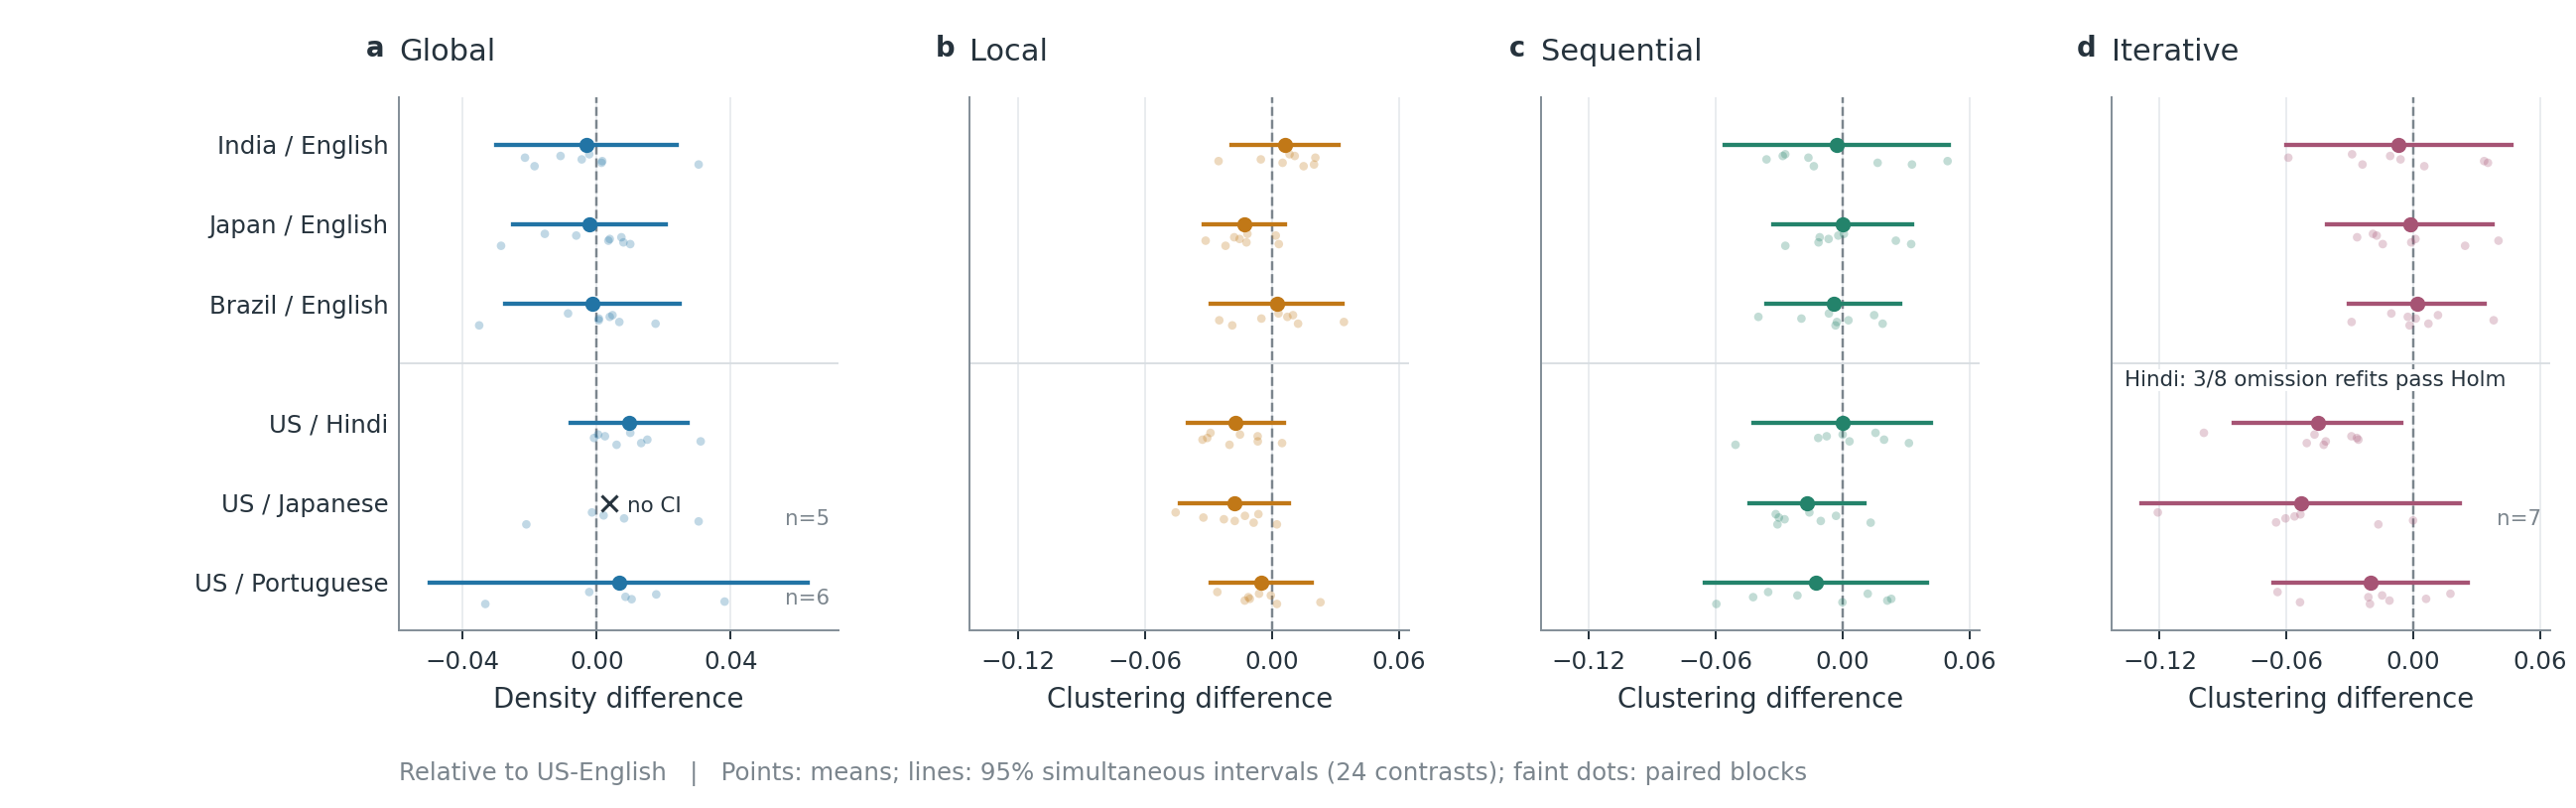

**Instruction contrasts.** All 24 planned contrasts are retained. Colored points
are complete-block means, horizontal lines are the archived 95% simultaneous
Bonferroni t intervals for the 24-contrast family, and faint dots are individual
complete paired blocks. Each block averages the same four fixed models before
subtracting same-seed US-English. The top three rows change country framing;
the bottom three change language while retaining US framing. Most rows have
eight blocks; the three exceptions are labeled. Global Japanese has five and
therefore no interval or primary test. Global uses density; the other panels
use clustering and share an axis range. Zero denotes no difference, not
equivalence. Assumptions and missingness limits remain unchanged. Iterative US-Hindi passes the adjusted threshold in only 3 of 8 omission refits; these are overlapping sensitivity checks.

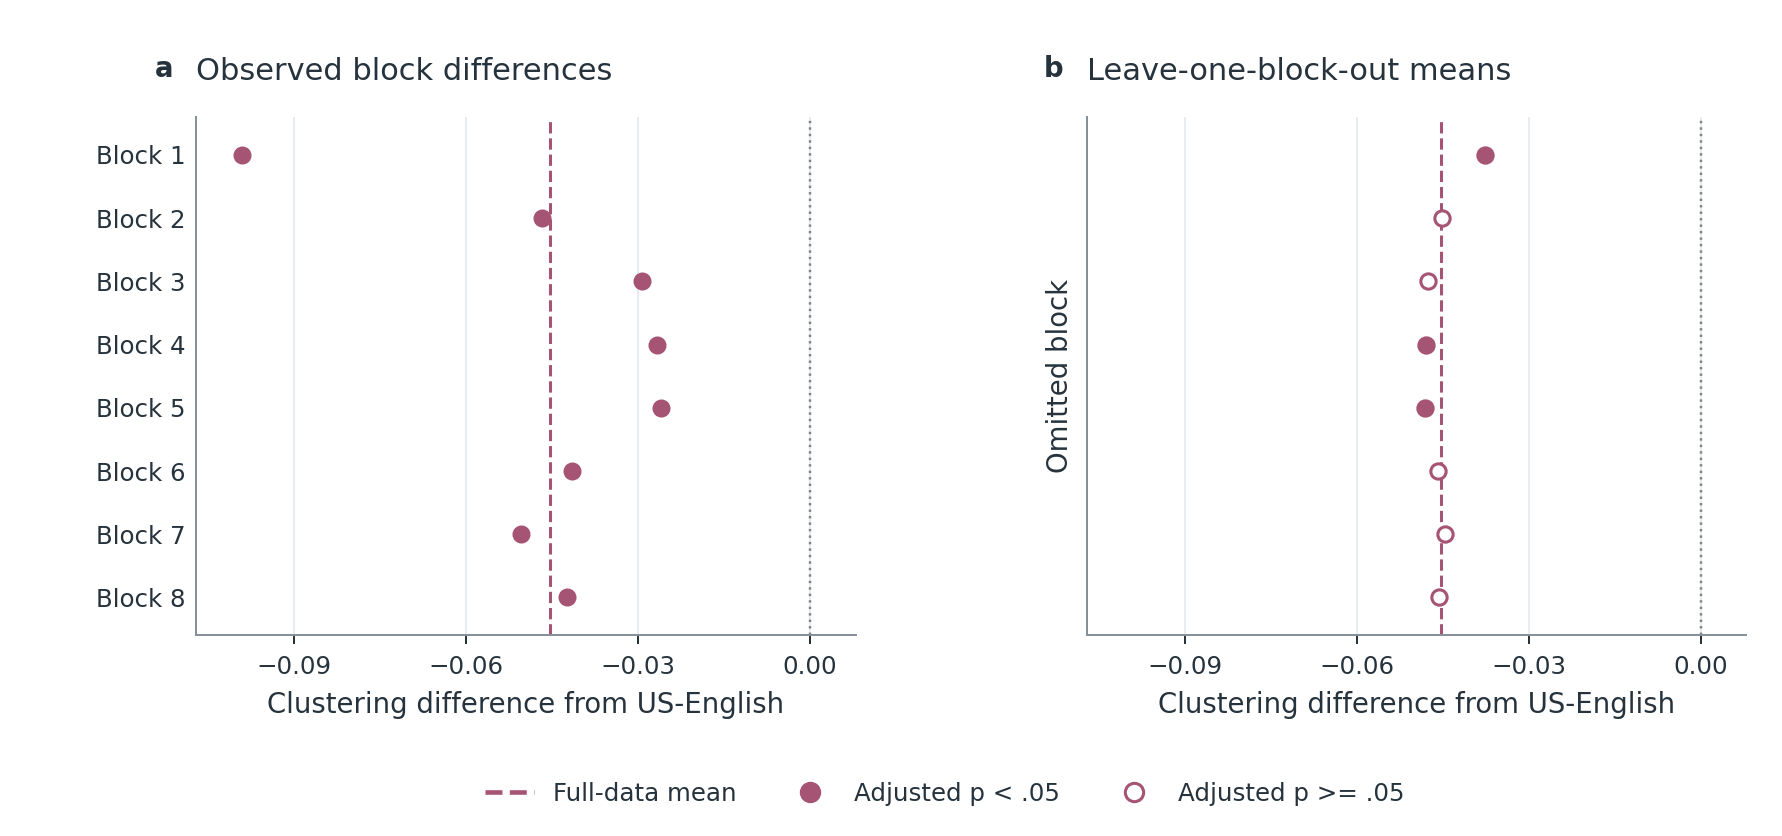

**Sensitivity of iterative US-Hindi.** Left: all eight paired block differences.
Right: means after omitting the indicated block; blocks 1-8 correspond to seeds
44000-44007. The dashed line is the full-data mean, -0.045279. Filled refit
markers pass the full-family Holm threshold, open markers do not (3/8 pass).
No refit intervals are shown. Overlapping leave-one-out fits are not independent
replications, and 3/8 is not a probability of replication. The separate exact
sign-flip diagnostic has adjusted p=0.1875. This selected sensitivity view is
not a new confirmatory analysis or a statement about Hindi speakers.

In [4]:
display(json.loads((OUT / 'graph_evaluation.json').read_text()))
display(pd.read_csv(OUT / 'resources_by_method_model.csv'))
display(json.loads((OUT / 'resource_accounting.json').read_text()))
display(pd.read_csv(OUT / 'model_contrasts_descriptive.csv').query("hypothesis_id == 'iterative:us:hindi'"))
show(ROOT, ['01_primary_contrasts', '02_primary_robustness'])


## Real-world structural evaluation: descriptive, post-collection
The eight archived friendship networks reproduce the published node/edge anchors in Chang et al. Appendix C.3. Their populations, tie definitions and sizes differ from our fictional 50-person roster. Two Tailor waves share workers; repeated Moreno ratings are unioned. These are not eight independent national ground truths.
Comparisons report distributions, means and ECDF distances without KS p-values or a fitted winner. Structural similarity cannot validate political homophily, national behavior, language fidelity or real people. See empirical_evaluation.json for the exact projection and limitations.

,reference,nodes,edges,density,avg_clustering_coef,global_efficiency,tie_definition
0,Galesburg,31,63,0.135484,0.279826,0.445090,physician friendship nominations
1,Hi-tech,36,91,0.144444,0.415549,0.425873,employee personal-friend nominations
2,Karate,34,78,0.139037,0.570638,0.492008,karate club social ties
3,Prison,67,142,0.064224,0.309908,0.357070,inmate closest-friend nominations
4,Tailor 1,39,158,0.213225,0.458030,0.566914,"sociational ties, wave 1"
5,Tailor 2,39,223,0.300945,0.497703,0.638327,"sociational ties, wave 2; same workers as wave 1"
6,Moreno freshmen,31,218,0.468817,0.636112,0.731900,"positive friendship ratings, repeated observat..."
7,Moreno high school,70,274,0.113458,0.464907,0.446901,"positive friendship ratings, repeated observat..."


,method,model,metric,primary_attempts,primary_defined,reference_networks,primary_mean,reference_mean,reference_min,reference_max,mean_difference,ecdf_sup_distance,descriptive_only
0,global,gpt-4.1,density,56,56,8,0.041152,0.197454,0.064224,0.468817,-0.156303,1.000000,True
1,global,gpt-4.1,avg_clustering_coef,56,56,8,0.146690,0.454084,0.279826,0.636112,-0.307394,0.821429,True
2,global,gpt-4.1,global_efficiency,56,56,8,0.120740,0.513010,0.357070,0.731900,-0.392270,1.000000,True
3,global,gpt-5.6-luna,density,56,53,8,0.078244,0.197454,0.064224,0.468817,-0.119210,0.761792,True
4,global,gpt-5.6-luna,avg_clustering_coef,56,53,8,0.264353,0.454084,0.279826,0.636112,-0.189732,0.655660,True
5,global,gpt-5.6-luna,global_efficiency,56,53,8,0.319685,0.513010,0.357070,0.731900,-0.193325,0.818396,True
6,global,gpt-6-luna,density,56,55,8,0.051592,0.197454,0.064224,0.468817,-0.145863,0.838636,True
7,global,gpt-6-luna,avg_clustering_coef,56,55,8,0.206775,0.454084,0.279826,0.636112,-0.247310,0.636364,True
8,global,gpt-6-luna,global_efficiency,56,55,8,0.203244,0.513010,0.357070,0.731900,-0.309766,0.927273,True
9,global,gpt-6-sol,density,56,55,8,0.073202,0.197454,0.064224,0.468817,-0.124252,0.875000,True


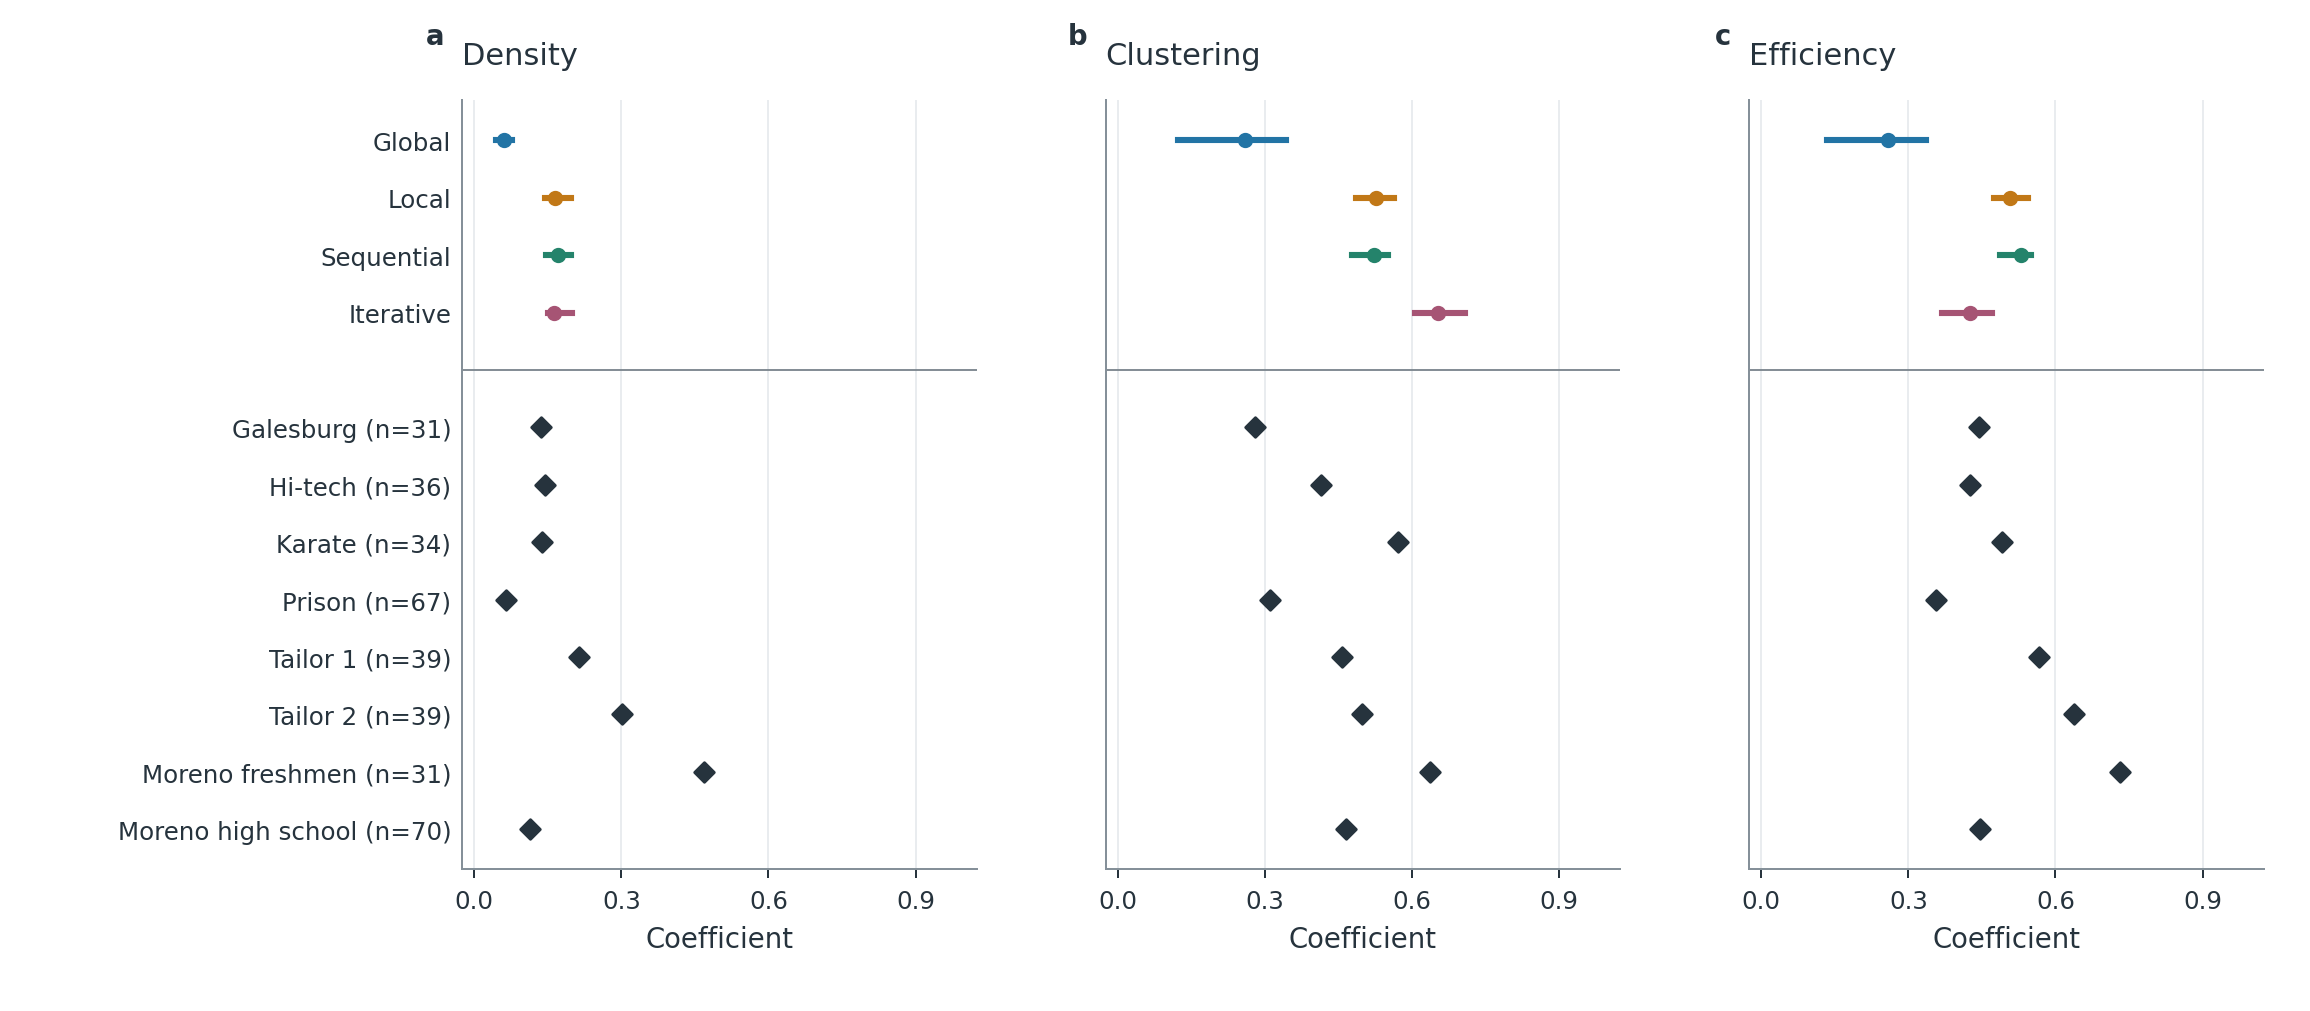

Circles show the median and lines the middle half of valid, defined primary outcomes within each procedure. These are distribution summaries, not confidence intervals. Diamonds are individual development records; size and tie definitions differ, and the Tailor waves share workers.

In [5]:
display(pd.read_csv(OUT / 'empirical_reference_metrics.csv')[['reference','nodes','edges','density','avg_clustering_coef','global_efficiency','tie_definition']])
display(pd.read_csv(OUT / 'empirical_comparisons_descriptive.csv'))
show(ROOT, ['07_legacy_comparison'])


## Findings in simple words
- The frozen t-test family finds one adjusted contrast: lower clustering for the iterative Hindi instruction contract versus US-English. It is about these specific instructions, not Hindi speakers or India.
- The direction is consistently negative, but adjusted significance is fragile: it remains below .05 in three of eight leave-one-seed-out runs, and no sign-flip contrast passes full-family adjustment. Treat it as assumption-dependent evidence, not a settled general effect.
- Most comparisons lack adjusted evidence; that does not prove no difference. One global Japanese contrast is not tested because only five complete blocks remain.
- Failed/empty graphs, a single roster, eight blocks, fixed model versions, unvalidated translation equivalence and unequal computation limit the claims. Real-network structural context is now included, but matched human behavioral validation is still absent.
- The professor's exact five papers are reviewed in docs/PRIMARY_LITERATURE_REVIEW.md as references, not targets our results must resemble. The strongest next step is preregistered, held-out real-world evaluation with matched tie semantics and appropriate consent.

Reproduce all derived tables and figures offline from the checkout root:
```powershell
rtk proxy .\.venv\Scripts\python.exe -I -B scripts\run_primary_evaluation.py
```
A fresh clone needs the hash-verified release ZIPs unpacked for raw receipt/resource regeneration; see ANALYSIS_START_HERE.md. No API key is needed.